In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "2"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer




bc_df = pd.read_csv("datasets/Breast-Cancer-Wisconsin-(Diagnostic)-Data-Set.csv")
pd.set_option("display.max_rows", 20)
bc_df.tail(10)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
559,925291,B,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,...,12.480,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732
560,925292,B,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,...,15.300,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321
561,925311,B,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,...,11.920,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905
562,925622,M,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,...,17.520,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090
563,926125,M,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,...,24.290,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039


In [3]:
bc_df_rounded_example = bc_df.round()
bc_df_rounded_example

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,18.0,10.0,123.0,1001.0,0.0,0.0,0.0,0.0,...,25.0,17.0,185.0,2019.0,0.0,1.0,1.0,0.0,0.0,0.0
1,842517,M,21.0,18.0,133.0,1326.0,0.0,0.0,0.0,0.0,...,25.0,23.0,159.0,1956.0,0.0,0.0,0.0,0.0,0.0,0.0
2,84300903,M,20.0,21.0,130.0,1203.0,0.0,0.0,0.0,0.0,...,24.0,26.0,152.0,1709.0,0.0,0.0,0.0,0.0,0.0,0.0
3,84348301,M,11.0,20.0,78.0,386.0,0.0,0.0,0.0,0.0,...,15.0,26.0,99.0,568.0,0.0,1.0,1.0,0.0,1.0,0.0
4,84358402,M,20.0,14.0,135.0,1297.0,0.0,0.0,0.0,0.0,...,23.0,17.0,152.0,1575.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,22.0,22.0,142.0,1479.0,0.0,0.0,0.0,0.0,...,25.0,26.0,166.0,2027.0,0.0,0.0,0.0,0.0,0.0,0.0
565,926682,M,20.0,28.0,131.0,1261.0,0.0,0.0,0.0,0.0,...,24.0,38.0,155.0,1731.0,0.0,0.0,0.0,0.0,0.0,0.0
566,926954,M,17.0,28.0,108.0,858.0,0.0,0.0,0.0,0.0,...,19.0,34.0,127.0,1124.0,0.0,0.0,0.0,0.0,0.0,0.0
567,927241,M,21.0,29.0,140.0,1265.0,0.0,0.0,0.0,0.0,...,26.0,39.0,185.0,1821.0,0.0,1.0,1.0,0.0,0.0,0.0


In [4]:
y = bc_df.loc[:,"diagnosis"]
X = bc_df.loc[:,"radius_mean":]
bc_df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [5]:
def sig_fig_round(num, sig):
    if num==0:
        return 0
    return np.round(num, sig - int(np.floor(np.log10(abs(num)))) - 1)


In [6]:

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=.8, random_state=42)

In [ ]:
models = {"logreg": LogisticRegression(max_iter=10000), "svc": SVC(), "dt":DecisionTreeClassifier(), "knc":KNeighborsClassifier()}
precision_values = {"rounding": [1,2,3,4,5,6], "uniform binning": [2,3,4,5,6], "quantile binning": [2,3,4,5,6], "kmeans binning": [2,3,4,5,6], "sig figs": [1,2,3,4,5,6]}
modes = ["both", "training_data_only", "testing_data_only"]
bc_results = []
# huh = 0
for model_name, model in models.items():
    base_model = model.__class__(**model.get_params())
    base_model.fit(X_train, y_train)
    base_acc = base_model.score(X_test,y_test)

    bc_results.append({"method":"base", "model": model_name, "level": 0, "mode": "base", "accuracy": base_acc})

    for method, levels in precision_values.items():
        for level in levels:
            for mode in modes:

                X_train_new = X_train.copy()
                X_test_new = X_test.copy()

                if method == "rounding":
                    if mode == "both":
                        X_train_new = X_train_new.round(level)
                        X_test_new = X_test_new.round(level)
                        print(X_train_new.iloc[0])
                        print(X_test_new.iloc[0])
                    elif mode == "training_data_only":
                        X_train_new = X_train_new.round(level)
                    elif mode == "testing_data_only":
                        X_test_new = X_test_new.round(level)

                elif method == "uniform binning":
                    kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy="uniform")
                    kbd.fit(X_train_new)
                    if mode == "both":
                        X_train_new = pd.DataFrame(kbd.inverse_transform(kbd.transform(X_train_new)))
                        X_test_new  = pd.DataFrame(kbd.inverse_transform(kbd.transform(X_test_new)))
                        print(X_train_new.iloc[0])
                        print(X_test_new.iloc[0])
                    elif mode == "training_data_only":
                        X_train_new = pd.DataFrame(kbd.transform(X_train_new), columns=X_train.columns)
                        X_train_new = pd.DataFrame(kbd.inverse_transform(X_train_new), columns=X_train.columns)
                    elif mode == "testing_data_only": 
                        X_test_new = pd.DataFrame(kbd.transform(X_test_new), columns=X_test.columns)
                        X_test_new = pd.DataFrame(kbd.inverse_transform(X_test_new), columns=X_test.columns)
                
                elif method == "quantile binning":
                    kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy="quantile")
                    kbd.fit(X_train_new)
                    if mode == "both":
                        X_train_new = kbd.inverse_transform(kbd.transform(X_train_new))
                        X_test_new  = kbd.inverse_transform(kbd.transform(X_test_new)) 
                        
                    elif mode == "training_data_only":
                        X_train_new = pd.DataFrame(kbd.transform(X_train_new), columns=X_train.columns)
                        X_train_new = pd.DataFrame(kbd.inverse_transform(X_train_new), columns=X_train.columns)
                    elif mode == "testing_data_only":
                        X_test_new = pd.DataFrame(kbd.transform(X_test_new), columns=X_test.columns)
                        X_test_new = pd.DataFrame(kbd.inverse_transform(X_test_new), columns=X_test.columns)
                
                elif method == "kmeans binning":
                    kbd = KBinsDiscretizer(n_bins=level, encode="ordinal", strategy="kmeans", )
                    kbd.fit(X_train_new)
                    if mode == "both":
                        X_train_new = kbd.inverse_transform(kbd.transform(X_train_new))
                        X_test_new  = kbd.inverse_transform(kbd.transform(X_test_new)) 
                    elif mode == "training_data_only":
                        X_train_new = pd.DataFrame(kbd.transform(X_train_new), columns=X_train.columns)
                        X_train_new = pd.DataFrame(kbd.inverse_transform(X_train_new), columns=X_train.columns)
                    elif mode == "testing_data_only":
                        X_test_new = pd.DataFrame(kbd.transform(X_test_new), columns=X_test.columns)
                        X_test_new = pd.DataFrame(kbd.inverse_transform(X_test_new), columns=X_test.columns)
                
                elif method == "sig figs":
                    if mode == "both":
                        X_train_new = X_train_new.map(lambda num: sig_fig_round(num, level))
                        X_test_new = X_test_new.map(lambda num: sig_fig_round(num, level))
                        print(X_train_new.iloc[0])
                        print(X_test_new.iloc[0])
                    elif mode == "training_data_only":
                        X_train_new = X_train_new.map(lambda num: sig_fig_round(num, level))
                    elif mode == "testing_data_only":
                        X_test_new = X_test_new.map(lambda num: sig_fig_round(num, level))

                exp_model = model.__class__(**model.get_params())
                exp_model.fit(X_train_new, y_train)

                exp_acc = exp_model.score(X_test_new, y_test)
                # if method=="quantile binning" and level==2 and mode == "both":
                #     huh += 1

                
                bc_results.append({"method": method, "model":model_name, "level": level, "mode": mode, "accuracy":exp_acc})


radius_mean                  9.0
texture_mean                17.3
perimeter_mean              58.8
area_mean                  250.5
smoothness_mean              0.1
compactness_mean             0.1
concavity_mean               0.3
concave points_mean          0.0
symmetry_mean                0.2
fractal_dimension_mean       0.1
radius_se                    0.3
texture_se                   1.2
perimeter_se                 1.9
area_se                     17.7
smoothness_se                0.0
compactness_se               0.1
concavity_se                 0.3
concave points_se            0.0
symmetry_se                  0.0
fractal_dimension_se         0.0
radius_worst                10.3
texture_worst               22.6
perimeter_worst             65.5
area_worst                 324.7
smoothness_worst             0.1
compactness_worst            0.4
concavity_worst              1.3
concave points_worst         0.2
symmetry_worst               0.4
fractal_dimension_worst      0.1
Name: 68, 

c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 10000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i

radius_mean                  9.00
texture_mean                20.00
perimeter_mean              60.00
area_mean                  300.00
smoothness_mean              0.10
compactness_mean             0.10
concavity_mean               0.30
concave points_mean          0.04
symmetry_mean                0.20
fractal_dimension_mean       0.08
radius_se                    0.30
texture_se                   1.00
perimeter_se                 2.00
area_se                     20.00
smoothness_se                0.01
compactness_se               0.09
concavity_se                 0.30
concave points_se            0.03
symmetry_se                  0.04
fractal_dimension_se         0.01
radius_worst                10.00
texture_worst               20.00
perimeter_worst             70.00
area_worst                 300.00
smoothness_worst             0.10
compactness_worst            0.40
concavity_worst              1.00
concave points_worst         0.20
symmetry_worst               0.40
fractal_dimens

c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quanti

radius_mean                  9.00
texture_mean                20.00
perimeter_mean              60.00
area_mean                  300.00
smoothness_mean              0.10
compactness_mean             0.10
concavity_mean               0.30
concave points_mean          0.04
symmetry_mean                0.20
fractal_dimension_mean       0.08
radius_se                    0.30
texture_se                   1.00
perimeter_se                 2.00
area_se                     20.00
smoothness_se                0.01
compactness_se               0.09
concavity_se                 0.30
concave points_se            0.03
symmetry_se                  0.04
fractal_dimension_se         0.01
radius_worst                10.00
texture_worst               20.00
perimeter_worst             70.00
area_worst                 300.00
smoothness_worst             0.10
compactness_worst            0.40
concavity_worst              1.00
concave points_worst         0.20
symmetry_worst               0.40
fractal_dimens

c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quanti

radius_mean                  9.00
texture_mean                20.00
perimeter_mean              60.00
area_mean                  300.00
smoothness_mean              0.10
compactness_mean             0.10
concavity_mean               0.30
concave points_mean          0.04
symmetry_mean                0.20
fractal_dimension_mean       0.08
radius_se                    0.30
texture_se                   1.00
perimeter_se                 2.00
area_se                     20.00
smoothness_se                0.01
compactness_se               0.09
concavity_se                 0.30
concave points_se            0.03
symmetry_se                  0.04
fractal_dimension_se         0.01
radius_worst                10.00
texture_worst               20.00
perimeter_worst             70.00
area_worst                 300.00
smoothness_worst             0.10
compactness_worst            0.40
concavity_worst              1.00
concave points_worst         0.20
symmetry_worst               0.40
fractal_dimens

c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
c:\Users\abelg\anaconda3\envs\ress\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quanti

radius_mean                  9.00
texture_mean                20.00
perimeter_mean              60.00
area_mean                  300.00
smoothness_mean              0.10
compactness_mean             0.10
concavity_mean               0.30
concave points_mean          0.04
symmetry_mean                0.20
fractal_dimension_mean       0.08
radius_se                    0.30
texture_se                   1.00
perimeter_se                 2.00
area_se                     20.00
smoothness_se                0.01
compactness_se               0.09
concavity_se                 0.30
concave points_se            0.03
symmetry_se                  0.04
fractal_dimension_se         0.01
radius_worst                10.00
texture_worst               20.00
perimeter_worst             70.00
area_worst                 300.00
smoothness_worst             0.10
compactness_worst            0.40
concavity_worst              1.00
concave points_worst         0.20
symmetry_worst               0.40
fractal_dimens

In [18]:
pd.set_option("display.max_rows", None)
bc_results = pd.DataFrame(bc_results)
bc_results

,method,model,level,mode,accuracy
0,base,logreg,0,base,0.956140
1,rounding,logreg,1,both,0.956140
2,rounding,logreg,1,training_data_only,0.956140
3,rounding,logreg,1,testing_data_only,0.956140
4,rounding,logreg,2,both,0.956140
5,rounding,logreg,2,training_data_only,0.956140
6,rounding,logreg,2,testing_data_only,0.956140
7,rounding,logreg,3,both,0.956140
8,rounding,logreg,3,training_data_only,0.956140
9,rounding,logreg,3,testing_data_only,0.956140


In [9]:
data = pd.Series([2.3, 5.1, 7.8, 1.2, 9.0, 4.5, 6.7, 3.3])

binned = pd.cut(data, bins=3)

print(binned)

0    (1.192, 3.8]
1      (3.8, 6.4]
2      (6.4, 9.0]
3    (1.192, 3.8]
4      (6.4, 9.0]
5      (3.8, 6.4]
6      (6.4, 9.0]
7    (1.192, 3.8]
dtype: category
Categories (3, interval[float64, right]): [(1.192, 3.8] < (3.8, 6.4] < (6.4, 9.0]]


In [10]:
X_thing = np.array([[2.3],
              [5.1],
              [7.8],
              [1.2],
              [9.0],
              [4.5]])

kbd = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',      
    strategy='uniform'     
)

X_binned = kbd.fit_transform(X_thing)

print("Binned values:")
print(X_binned)

print("Bin edges:")
print(kbd.bin_edges_)
print(kbd.inverse_transform(X_binned))

Binned values:
[[0.]
 [1.]
 [2.]
 [0.]
 [2.]
 [1.]]
Bin edges:
[array([1.2, 3.8, 6.4, 9. ])]
[[2.5]
 [5.1]
 [7.7]
 [2.5]
 [7.7]
 [5.1]]


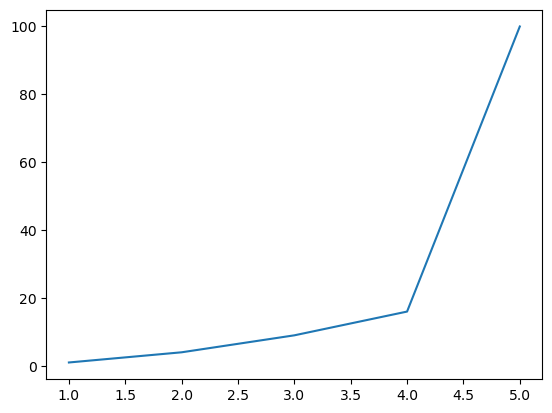

In [11]:
plt.plot([1,2,3,4,5],[1,4,9,16,100])
plt.show()

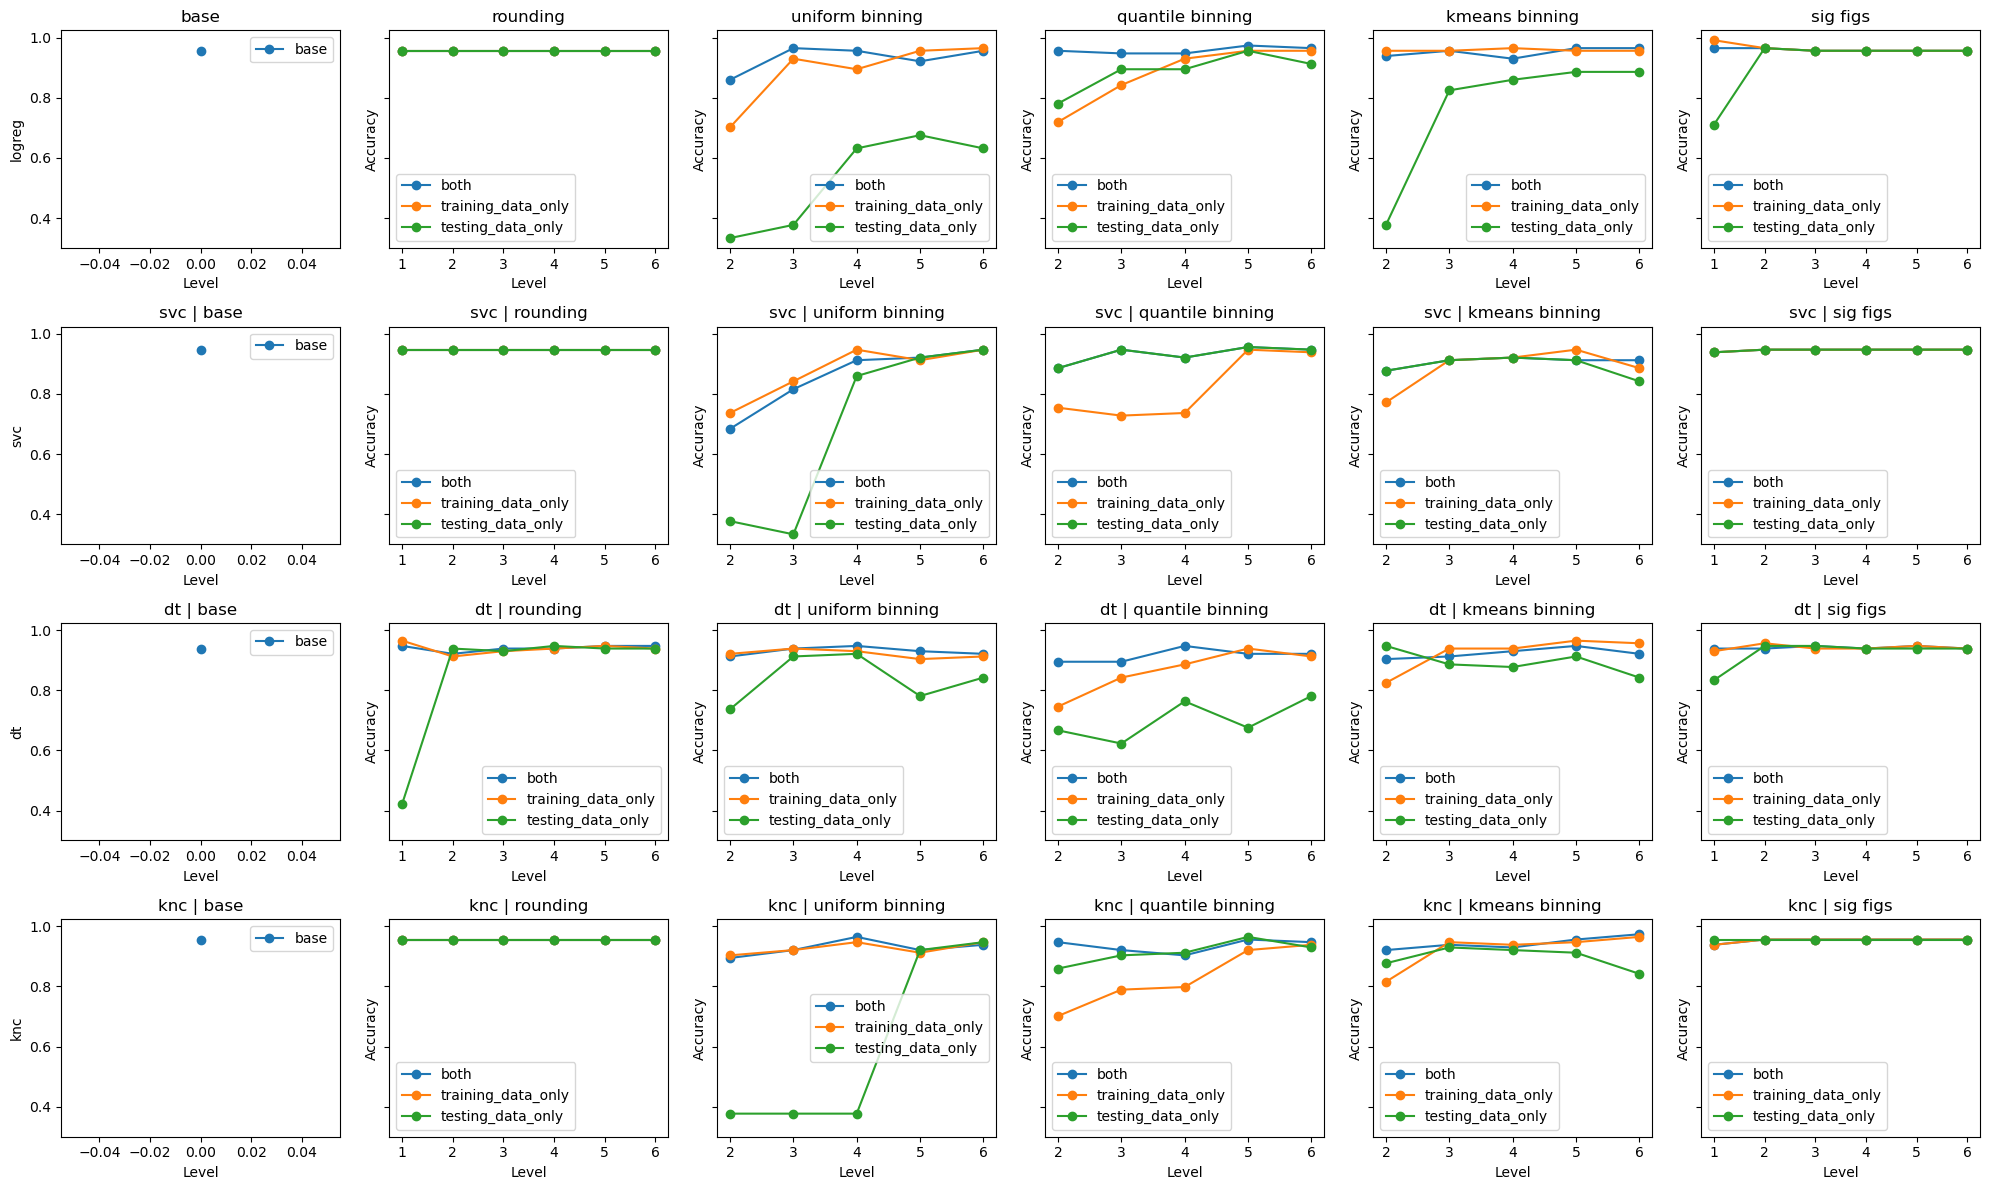

In [19]:

models = bc_results['model'].unique()
methods = bc_results['method'].unique()

fig, axes = plt.subplots(len(models), len(methods), figsize=(20, 12), sharey=True)

for i, model in enumerate(models):
    for j, method in enumerate(methods):
        ax = axes[i, j]

        subset = bc_results[(bc_results['model'] == model) & (bc_results['method'] == method)]

        # plot each mode as a line
        for mode in subset['mode'].unique():
            mode_data = subset[subset['mode'] == mode]
            ax.plot(mode_data['level'], mode_data['accuracy'], marker='o', label=mode)

        ax.set_title(f"{model} | {method}")
        ax.set_xlabel("Level")
        ax.set_ylabel("Accuracy")

        if i == 0:
            ax.set_title(method)
        if j == 0:
            ax.set_ylabel(model)

        ax.legend()

plt.tight_layout()
plt.show()

In [13]:
print(os.environ.get("OMP_NUM_THREADS"))

2
